In [121]:
import pandas as pd

df = pd.read_csv("karmanta_clean.csv")
df

,Employee_ID,Age,Attrition,Business_Travel,Sub-department,Distance_From_Home,Education,Environment_Satisfaction,Gender,Salary,...,Number_of_Companies_Worked_previously,Overtime,Salary_Hike_in_percent,Total_working_years_experience,Work_life_balance,No_of_years_worked_at_current_company,No_of_years_in_current_role,Years_since_last_promotion,Native_Place,External_experience
0,1,56.0,Yes,Travel Rarely,Network Administration,24,Graduation,5,Male,186630,...,7,Yes,85,9,1,7,2,4,Hyderabad,2
1,2,46.0,Yes,Travel Rarely,Software Development,45,Degree,5,Male,78553,...,3,No,22,18,4,1,2,0,Chennai,17
2,3,32.0,No,No Travel,Data Science,30,Master's,3,Female,175003,...,2,Yes,100,5,4,5,5,8,Lucknow,0
3,4,60.0,Yes,Travel Frequently,Data Science,42,Graduation,2,Female,100795,...,5,No,72,17,2,1,7,3,Lucknow,16
4,5,25.0,No,No Travel,Network Administration,26,Graduation,4,Female,75256,...,9,No,21,12,5,7,2,4,Lucknow,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9983,9996,33.0,Yes,Travel Frequently,Data Science,35,Degree,4,Male,108566,...,5,No,68,2,2,1,4,4,Hyderabad,1
9984,9997,62.0,No,Travel Rarely,Data Science,30,Degree,5,Female,115593,...,3,Yes,55,4,1,0,1,2,Chennai,4
9985,9998,32.0,No,Travel Rarely,Data Science,44,Degree,4,Female,160923,...,1,No,87,12,5,8,0,1,Jaipur,4
9986,9999,18.0,Yes,Travel Rarely,Data Science,46,Graduation,2,Male,163365,...,9,Yes,79,10,3,8,8,3,Bengaluru,2


In [122]:
df["Attrition_flag"] = df["Attrition"].map({"Yes": 1, "No": 0})

In [123]:
df = df.drop(columns=["Employee_ID", "Attrition"])

In [124]:
X = df.drop("Attrition_flag", axis=1)
y = df["Attrition_flag"]

In [125]:
X = pd.get_dummies(X, drop_first=True)

In [126]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [127]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

c:\Users\shrey\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [128]:
y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)[:, 1]

In [129]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred))

Accuracy: 0.8103103103103103
ROC AUC: 0.7414827584719504
              precision    recall  f1-score   support

           0       0.82      0.98      0.89      1549
           1       0.74      0.24      0.36       449

    accuracy                           0.81      1998
   macro avg       0.78      0.61      0.63      1998
weighted avg       0.80      0.81      0.77      1998



In [130]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]

print("DT Accuracy:", accuracy_score(y_test, y_pred_dt))
print("DT ROC:", roc_auc_score(y_test, y_prob_dt))

DT Accuracy: 0.8483483483483484
DT ROC: 0.7931217927795935


In [131]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr.coef_[0]
}).sort_values(by="Coefficient", ascending=False)

importance.head(10)

,Feature,Coefficient
15,Business_Travel_Travel Frequently,0.134199
13,Years_since_last_promotion,0.129121
28,Overtime_Yes,0.050742
1,Distance_From_Home,0.030751
5,Job_Level,0.027946
7,Number_of_Companies_Worked_previously,0.012612
30,Native_Place_Chennai,0.012447
27,Marital_Status_Single,0.007447
24,Education_PhD,0.006778
12,No_of_years_in_current_role,0.005472


In [132]:
fi = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt.feature_importances_
}).sort_values(by="Importance", ascending=False)

fi.head(10)

,Feature,Importance
10,Work_life_balance,0.228045
1,Distance_From_Home,0.199147
2,Environment_Satisfaction,0.134466
4,Job_Involvement,0.110501
6,Job_Satisfaction,0.102353
13,Years_since_last_promotion,0.100907
15,Business_Travel_Travel Frequently,0.066321
28,Overtime_Yes,0.047629
0,Age,0.005478
8,Salary_Hike_in_percent,0.001884


In [133]:
risk_df = pd.DataFrame({
    "Probability": y_prob
})

def risk_level(p):
    if p > 0.6:
        return "High"
    elif p > 0.3:
        return "Medium"
    else:
        return "Low"

risk_df["Risk"] = risk_df["Probability"].apply(risk_level)

risk_df["Risk"].value_counts()

Risk
Low       1460
Medium     474
High        64
Name: count, dtype: int64

In [134]:
results = X_test.copy()
results["Actual"] = y_test.values
results["Probability"] = y_prob
results["Risk"] = risk_df["Risk"].values

results

,Age,Distance_From_Home,Environment_Satisfaction,Salary,Job_Involvement,Job_Level,Job_Satisfaction,Number_of_Companies_Worked_previously,Salary_Hike_in_percent,Total_working_years_experience,...,Native_Place_Delhi,Native_Place_Hyderabad,Native_Place_Jaipur,Native_Place_Kolkata,Native_Place_Lucknow,Native_Place_Mumbai,Native_Place_Pune,Actual,Probability,Risk
9482,45.0,12,3,172053,3,3,1,4,17,18,...,False,False,False,False,False,False,False,0,0.176946,Low
5686,35.0,14,5,64997,5,2,2,2,64,10,...,False,True,False,False,False,False,False,0,0.043323,Low
9226,57.0,3,4,105869,3,1,1,9,11,7,...,False,False,False,True,False,False,False,1,0.053900,Low
6536,53.0,43,1,170424,2,6,2,3,51,19,...,False,False,False,False,False,False,True,1,0.432526,Medium
5297,41.0,26,4,36782,4,1,4,9,51,15,...,True,False,False,False,False,False,False,0,0.045772,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6671,33.0,20,1,117095,4,6,2,7,11,3,...,True,False,False,False,False,False,False,0,0.166394,Low
6542,57.0,34,1,153831,2,4,5,10,71,5,...,False,False,False,False,False,True,False,1,0.506704,Medium
4984,28.0,47,2,32990,5,7,2,5,27,12,...,False,False,False,True,False,False,False,0,0.324819,Medium
8874,45.0,50,2,91056,3,1,4,6,99,9,...,False,False,True,False,False,False,False,0,0.229831,Low


In [135]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)
import matplotlib.pyplot as plt

## Log Reg Report

In [136]:
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

In [137]:
print("Accuracy:", accuracy_score(y_test, y_pred_lr))

Accuracy: 0.8103103103103103


In [138]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
print(cm_lr)

[[1511   38]
 [ 341  108]]


In [139]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.82      0.98      0.89      1549
           1       0.74      0.24      0.36       449

    accuracy                           0.81      1998
   macro avg       0.78      0.61      0.63      1998
weighted avg       0.80      0.81      0.77      1998



In [140]:
print("ROC AUC:", roc_auc_score(y_test, y_prob_lr))

ROC AUC: 0.7414827584719504


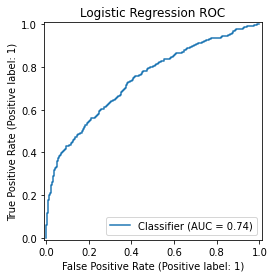

In [141]:
RocCurveDisplay.from_predictions(y_test, y_prob_lr)
plt.title("Logistic Regression ROC")
plt.show()

## DT Report

In [142]:
y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]

In [143]:
print("Accuracy:", accuracy_score(y_test, y_pred_dt))

Accuracy: 0.8483483483483484


In [144]:
cm_dt = confusion_matrix(y_test, y_pred_dt)
print(cm_dt)

[[1521   28]
 [ 275  174]]


In [145]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.85      0.98      0.91      1549
           1       0.86      0.39      0.53       449

    accuracy                           0.85      1998
   macro avg       0.85      0.68      0.72      1998
weighted avg       0.85      0.85      0.83      1998



In [146]:
print("ROC AUC:", roc_auc_score(y_test, y_prob_dt))

ROC AUC: 0.7931217927795935


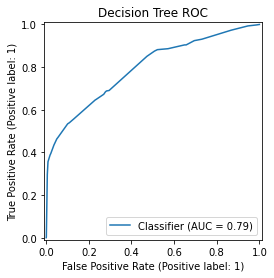

In [147]:
RocCurveDisplay.from_predictions(y_test, y_prob_dt)
plt.title("Decision Tree ROC")
plt.show()

## Both Models ROC

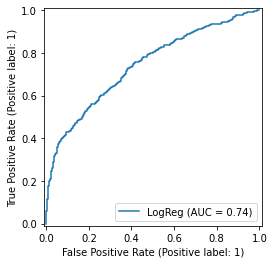

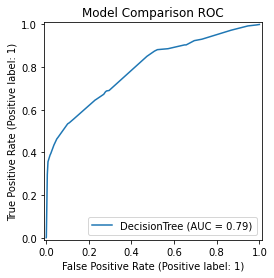

In [148]:
RocCurveDisplay.from_predictions(y_test, y_prob_lr, name="LogReg")
RocCurveDisplay.from_predictions(y_test, y_prob_dt, name="DecisionTree")
plt.title("Model Comparison ROC")
plt.show()

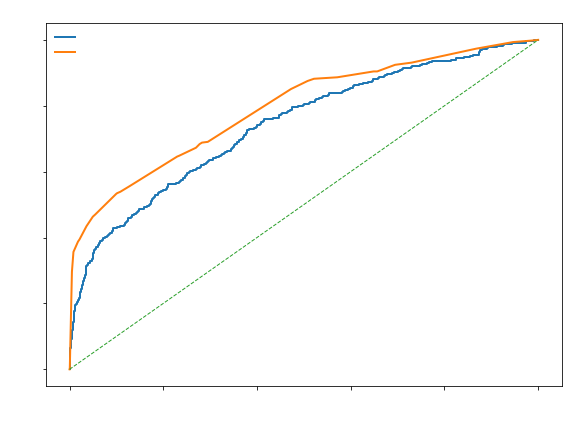

In [149]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# ROC points
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)

auc_lr = auc(fpr_lr, tpr_lr)
auc_dt = auc(fpr_dt, tpr_dt)

plt.figure(figsize=(8,6))

# Curves
plt.plot(fpr_lr, tpr_lr, linewidth=2, label=f"LogReg (AUC = {auc_lr:.2f})")
plt.plot(fpr_dt, tpr_dt, linewidth=2, label=f"Decision Tree (AUC = {auc_dt:.2f})")

# Random baseline
plt.plot([0,1], [0,1], linestyle="--", linewidth=1)

# Title & labels
plt.title("Model Comparison ROC", color="white", fontweight="bold", fontsize=14)
plt.xlabel("False Positive Rate", color="white", fontweight="bold")
plt.ylabel("True Positive Rate", color="white", fontweight="bold")

# Axis ticks
plt.xticks(color="white", fontweight="bold")
plt.yticks(color="white", fontweight="bold")

# Legend
leg = plt.legend(frameon=False)
for t in leg.get_texts():
    t.set_color("white")
    t.set_fontweight("bold")

# Make background transparent
plt.gca().set_facecolor("none")
plt.gcf().patch.set_alpha(0)

plt.tight_layout()
plt.show()

## Risk Profiling

In [150]:
original = pd.read_csv("karmanta_clean.csv")

test_original = original.loc[X_test.index].copy()

In [151]:
test_original["LR_Probability"] = y_prob_lr

def risk_bucket(p):
    if p > 0.6:
        return "High"
    elif p > 0.3:
        return "Medium"
    else:
        return "Low"

test_original["LR_Risk"] = test_original["LR_Probability"].apply(risk_bucket)

In [152]:
pd.DataFrame(test_original["LR_Risk"].value_counts())

,count
LR_Risk,
Low,1460
Medium,474
High,64


In [153]:
lr_high = test_original[test_original["LR_Risk"] == "High"]

lr_high.describe()

,Employee_ID,Age,Distance_From_Home,Environment_Satisfaction,Salary,Job_Involvement,Job_Level,Job_Satisfaction,Number_of_Companies_Worked_previously,Salary_Hike_in_percent,Total_working_years_experience,Work_life_balance,No_of_years_worked_at_current_company,No_of_years_in_current_role,Years_since_last_promotion,External_experience,LR_Probability
count,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000
mean,5234.781250,39.656250,39.390625,1.468750,119800.984375,1.546875,4.781250,2.125000,5.703125,51.531250,10.968750,1.687500,4.578125,4.453125,5.843750,6.390625,0.662278
std,3021.680303,13.173107,9.424078,0.776004,50915.815166,0.688446,2.471865,1.253566,3.240026,28.680489,5.500271,0.888641,2.921212,2.996981,1.844931,5.675392,0.054913
min,538.000000,18.000000,12.000000,1.000000,32644.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.600348
25%,2719.500000,28.000000,34.000000,1.000000,78594.000000,1.000000,2.750000,1.000000,3.750000,30.500000,7.000000,1.000000,2.750000,2.000000,5.000000,0.000000,0.619091
50%,4569.000000,41.000000,41.500000,1.000000,126865.000000,1.000000,5.000000,2.000000,6.000000,57.000000,10.000000,1.000000,5.000000,4.000000,6.000000,5.500000,0.647066
75%,8583.750000,50.000000,48.000000,2.000000,161843.750000,2.000000,7.000000,3.000000,9.000000,73.500000,16.250000,2.000000,7.000000,6.250000,7.000000,11.000000,0.686535
max,9970.000000,63.000000,50.000000,4.000000,196650.000000,3.000000,8.000000,5.000000,10.000000,100.000000,20.000000,4.000000,10.000000,10.000000,8.000000,20.000000,0.797466


In [154]:
lr_high.describe().to_csv("lr_high_summary.csv")

In [155]:
for col in ["Business_Travel", "Overtime", "Marital_Status", "Sub-department"]:
    print("\n", col)
    print(lr_high[col].value_counts(normalize=True) * 100)


 Business_Travel
Business_Travel
Travel Rarely        50.0000
No Travel            26.5625
Travel Frequently    23.4375
Name: proportion, dtype: float64

 Overtime
Overtime
No     65.625
Yes    34.375
Name: proportion, dtype: float64

 Marital_Status
Marital_Status
Divorced    40.625
Single      31.250
Married     28.125
Name: proportion, dtype: float64

 Sub-department
Sub-department
Network Administration    28.1250
Software Development      23.4375
Cyber Security            21.8750
Data Science              14.0625
IT Services               12.5000
Name: proportion, dtype: float64


In [156]:
test_original["DT_Probability"] = y_prob_dt
test_original["DT_Risk"] = test_original["DT_Probability"].apply(risk_bucket)

In [157]:
pd.DataFrame(test_original["DT_Risk"].value_counts())

,count
DT_Risk,
Low,1601
High,202
Medium,195


In [158]:
dt_high = test_original[test_original["DT_Risk"] == "High"]

dt_high.describe()

,Employee_ID,Age,Distance_From_Home,Environment_Satisfaction,Salary,Job_Involvement,Job_Level,Job_Satisfaction,Number_of_Companies_Worked_previously,Salary_Hike_in_percent,Total_working_years_experience,Work_life_balance,No_of_years_worked_at_current_company,No_of_years_in_current_role,Years_since_last_promotion,External_experience,LR_Probability,DT_Probability
count,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000,202.000000
mean,4991.707921,39.574257,33.272277,2.024752,113603.806931,2.217822,4.410891,2.712871,5.257426,50.861386,11.173267,1.965347,4.965347,4.638614,4.866337,6.207921,0.449448,0.917295
std,2841.583575,12.618274,13.090581,0.883447,48115.550643,1.266514,2.303897,1.444403,3.121594,29.246092,5.348983,1.057448,3.173865,3.248129,2.159546,5.635384,0.168457,0.101099
min,14.000000,18.000000,8.000000,1.000000,32693.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.122583,0.694215
25%,2546.250000,28.250000,23.000000,1.000000,75364.750000,1.000000,2.000000,1.000000,2.000000,24.750000,7.000000,1.000000,2.000000,2.000000,3.000000,0.000000,0.312515,0.857923
50%,4901.000000,41.000000,37.000000,2.000000,116505.500000,2.000000,4.000000,2.500000,5.000000,54.500000,11.000000,2.000000,5.000000,4.000000,5.000000,5.000000,0.447709,0.976143
75%,7481.250000,49.750000,45.000000,3.000000,148399.250000,3.000000,6.000000,4.000000,8.000000,73.750000,16.000000,2.000000,8.000000,7.000000,7.000000,10.750000,0.593913,0.976143
max,9970.000000,63.000000,50.000000,5.000000,199707.000000,5.000000,8.000000,5.000000,10.000000,100.000000,20.000000,5.000000,10.000000,10.000000,8.000000,20.000000,0.797466,1.000000


In [159]:
dt_high.describe().to_csv("dt_high_summary.csv")

In [160]:
for col in ["Business_Travel", "Overtime", "Marital_Status", "Sub-department"]:
    print("\n", col)
    print(dt_high[col].value_counts(normalize=True) * 100)


 Business_Travel
Business_Travel
Travel Rarely        54.455446
Travel Frequently    28.712871
No Travel            16.831683
Name: proportion, dtype: float64

 Overtime
Overtime
No     59.90099
Yes    40.09901
Name: proportion, dtype: float64

 Marital_Status
Marital_Status
Single      34.653465
Divorced    33.663366
Married     31.683168
Name: proportion, dtype: float64

 Sub-department
Sub-department
Network Administration    24.257426
Software Development      22.277228
Cyber Security            19.801980
IT Services               18.316832
Data Science              15.346535
Name: proportion, dtype: float64
